# Crescimento da demanda por Centro de Distribuição e Ponto de Venda

**Pergunta do time:** *qual centro de distribuição e qual ponto de venda têm o maior crescimento de demanda nos três meses previstos?*

**Resposta curta:** nos três meses previstos (setembro, outubro e novembro de 2026), o CD que mais cresce é o **Armazém Camargo** (+1.338 unidades do primeiro para o terceiro mês) e o PDV é a **Loja Oliveira** (+1.295). Mas o crescimento **percentual** é o mesmo em todos os seis locais — **89,8%** — porque a repartição mês a mês usa um único perfil sazonal para todas as séries. Isso significa que, dentro do horizonte, "quem mais cresce" é simplesmente "quem tem mais volume". Para separar os locais de verdade, este notebook também compara o trimestre previsto com o **mesmo trimestre realizado em 2025**: aí o CD que mais cresce é o **Armazém Novaes** (+9,6%) e o PDV continua sendo a **Loja Oliveira** (+31,5%).

**O que este notebook faz:**

1. lê a previsão mês a mês do GLM Poisson (notebook 06) e a dimensão de locais;
2. separa Centro de Distribuição (`location_type = warehouse`) de Ponto de Venda (`store`) e associa cada PDV a um CD;
3. calcula, por unidade, a demanda de cada mês previsto, as variações mês a mês e o crescimento do mês 1 para o mês 3 — em unidades e em percentual;
4. compara o trimestre previsto com set–nov/2025;
5. mostra quais produtos puxam o crescimento das unidades vencedoras;
6. confere se o GLM Tweedie conta a mesma história.

**Definições fixadas antes de olhar os números:**

- **Crescimento (principal)** = demanda prevista no mês 3 − demanda prevista no mês 1. O percentual fica ao lado, mas o ranking oficial é o absoluto: percentual infla quem parte de base pequena, e aqui ele nem sequer discrimina.
- **Crescimento frente ao ano anterior (complementar)** = previsto set+out+nov/2026 − realizado set+out+nov/2025.
- **Vínculo PDV → CD**: não existe nos dados (não há tabela de abastecimento, transferência ou CD responsável). Usa-se proximidade geográfica — mesma UF, senão mesma região — e isso deve ser lido como hipótese.
- Crescimento **não** é demanda acumulada: somar os três meses mede volume, não crescimento.


## Setup

In [1]:
import sys
from pathlib import Path


def _find_project_root(start: Path) -> Path:
    """Sobe a partir do diretório do notebook até achar a raiz do bundle (databricks.yml)."""
    for candidate in (start, *start.parents):
        if (candidate / "databricks.yml").exists():
            return candidate
    raise FileNotFoundError(f"databricks.yml não encontrado acima de {start}")


# Funciona no workspace (.bundle/.../files/notebooks/ml) e localmente.
PROJECT_ROOT = _find_project_root(Path.cwd())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

In [2]:
%matplotlib inline
import datetime as dt

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.analytics_ai.demand_growth import (
    CD,
    PDV,
    TIPO_LOCAL,
    concentracao,
    contribuicao_produtos,
    crescimento_vs_ano_anterior,
    enriquecer,
    evolucao_mensal,
    preparar_locais,
    trajetoria_por_unidade,
    validar_previsao_mensal,
)
from src.analytics_ai.ml_config import MlFeatureConfig, MlModelConfig

# No Databricks o notebook já expõe `spark`; localmente cria via Databricks Connect
# (defina DATABRICKS_PROFILE com o nome do seu profile em ~/.databrickscfg).
spark = globals().get("spark")
if spark is None:
    from src.ingestion.utils import build_spark_session

    spark = build_spark_session()

# Databricks e Jupyter injetam `display`; fora deles, cai para print.
display = globals().get("display", print)

plt.rcParams["figure.dpi"] = 100
CORES = ["#2E5C8A", "#E8874C", "#4C9A6A", "#B24C4C"]
COR_TIPO = {CD: CORES[0], PDV: CORES[1]}

model_config = MlModelConfig.from_environment()
monthly_config = MlFeatureConfig.from_environment_monthly()
MODELO = "glm_poisson"
# Realizado sem meses parciais: o mês corrente entra em agg_demand_monthly
# incompleto e distorceria qualquer comparação.
TABELA_REALIZADO = f"{monthly_config.catalog}.{monthly_config.schema}.ml_complete_monthly_demand"


def ler(tabela: str, filtro: str | None = None) -> pd.DataFrame:
    df = spark.table(tabela)
    if filtro:
        df = df.where(filtro)
    quadro = df.toPandas()
    quadro.attrs.clear()
    return quadro

## 1. Leitura e conferências

A previsão vem da tabela `ml_forecast_demanda_mensal`, partição do GLM Poisson — o modelo final do notebook 06. Antes de somar qualquer coisa, a tabela passa por uma validação que falha em vez de deixar NaN entrar nas contas: um único corte, uma linha por produto × loja × mês, sem nulos nem negativos, três horizontes em toda série.

In [3]:
mensal = ler(model_config.forecast_monthly_target, f"model_name = '{MODELO}'")
mensal["demanda_prevista"] = pd.to_numeric(mensal["demanda_prevista"]).astype(float)
dim_locais = ler(monthly_config.gold_table("dim_locations"))
produtos = ler(monthly_config.gold_table("dim_products"))[["sk_product", "sku", "product_name", "category_name"]]
real = ler(TABELA_REALIZADO)
real["demand_quantity"] = pd.to_numeric(real["demand_quantity"]).astype(float)

validar_previsao_mensal(mensal)
locais = preparar_locais(dim_locais)
previsao = enriquecer(mensal, locais)

CORTE = previsao["cutoff"].iloc[0]
MESES = sorted(previsao["mes_previsto"].unique())
print(f"previsão mensal: {len(previsao):,} linhas | corte {CORTE} | meses previstos {[str(m) for m in MESES]}")
print(f"{previsao['sk_product'].nunique():,} produtos x {previsao['sk_location'].nunique()} locais"
      f" = {previsao.groupby(['sk_product', 'sk_location']).ngroups:,} séries x 3 meses")
print(f"total previsto no trimestre: {previsao['demanda_prevista'].sum():,.1f} unidades (deve bater com o notebook 06)")
print(f"realizado: {len(real):,} linhas, de {real['month_start_date'].min()} a {real['month_start_date'].max()}")
print(f"locais: {(locais['location_type'] == CD).sum()} CD + {(locais['location_type'] == PDV).sum()} PDV")

previsão mensal: 18,162 linhas | corte 2026-08-01 | meses previstos ['2026-09-01', '2026-10-01', '2026-11-01']
1,009 produtos x 6 locais = 6,054 séries x 3 meses
total previsto no trimestre: 38,249.2 unidades (deve bater com o notebook 06)
realizado: 448,175 linhas, de 2020-01-01 a 2026-08-01
locais: 3 CD + 3 PDV


## 2. Os locais: CD, PDV e o vínculo entre eles

Nas tabelas do projeto não existe a palavra "CD" nem "PDV". O que existe é `dim_locations.location_type`, com dois valores: `warehouse` (armazém = centro de distribuição) e `store` (loja = ponto de venda). Também não existe nenhuma coluna ou tabela que diga qual armazém abastece qual loja — `stock_movements` só registra venda, compra e devolução, sem origem e destino. O vínculo abaixo é, portanto, uma **hipótese de proximidade**: a loja fica com o armazém da mesma UF; se não houver, com o da mesma região.

In [4]:
display(
    locais[["location_name", "tipo", "state", "region", "cd_associado", "criterio_vinculo"]]
    .sort_values(["tipo", "location_name"])
    .reset_index(drop=True)
)
sem_cd = locais[(locais["location_type"] == PDV) & locais["cd_sk_location"].isna()]
print(f"PDV sem CD associado: {len(sem_cd)} | vínculos ambíguos: {int(locais['ambiguo'].sum())}")
print("CD sem nenhum PDV:", ", ".join(
    sorted(set(locais.loc[locais["location_type"] == CD, "location_name"]) - set(locais["cd_associado"].dropna()))
) or "nenhum")

,location_name,tipo,state,region,cd_associado,criterio_vinculo
0,Armazém Camargo,Centro de Distribuição,PR,Sul,NaN,NaN
1,Armazém Novaes,Centro de Distribuição,PI,Nordeste,NaN,NaN
2,Armazém Siqueira,Centro de Distribuição,AP,Norte,NaN,NaN
3,Loja Leão,Ponto de Venda,PR,Sul,Armazém Camargo,mesma UF
4,Loja Mendonça,Ponto de Venda,PI,Nordeste,Armazém Novaes,mesma UF
5,Loja Oliveira,Ponto de Venda,AL,Nordeste,Armazém Novaes,mesma região


PDV sem CD associado: 0 | vínculos ambíguos: 0
CD sem nenhum PDV: Armazém Siqueira


**O que a tabela mostra:** três armazéns e três lojas. Duas lojas têm armazém na própria UF (Leão ↔ Camargo, no PR; Mendonça ↔ Novaes, no PI). A Loja Oliveira (AL) não tem armazém no estado e fica com o Novaes, o único do Nordeste. O Armazém Siqueira (AP, Norte) não tem loja alguma por perto — pela hipótese geográfica, ele não abastece nenhum PDV.

## 3. Como o crescimento é medido — e uma propriedade que muda a leitura

Para cada unidade `u` (um CD ou um PDV), `D_u(k)` é a soma da demanda prevista de todos os produtos no mês `k`:

```
variação 1→2      = D(2) − D(1)          e em %:  (D(2) / D(1) − 1) × 100
variação 2→3      = D(3) − D(2)
crescimento 1→3   = D(3) − D(1)          ← resposta principal
```

Antes de olhar as unidades, vale conferir uma propriedade da previsão. O notebook 06 reparte o total de 3 meses pelos índices sazonais da tabela de features — e esses índices são **os mesmos para todas as séries** de um mesmo corte (o índice sazonal é geral, decisão da Etapa 2). Se isso for verdade, a fração de cada mês (`share_sazonal`) tem um único valor por mês, e o crescimento percentual entre dois meses é idêntico em todo lugar: `D(3)/D(1) = share_3/share_1`, independentemente da unidade.

In [5]:
shares = previsao.groupby("mes_previsto")["share_sazonal"].agg(["nunique", "first"]).rename(
    columns={"nunique": "valores distintos", "first": "share"}
)
display(shares)
s1, s3 = shares["share"].iloc[0], shares["share"].iloc[-1]
print(f"crescimento percentual implícito do mês 1 para o mês 3, igual para toda série: {(s3 / s1 - 1) * 100:.2f}%")

,valores distintos,share
mes_previsto,,
2026-09-01,1,0.225379
2026-10-01,1,0.346933
2026-11-01,1,0.427688


crescimento percentual implícito do mês 1 para o mês 3, igual para toda série: 89.76%


**O que a tabela mostra:** um único valor de `share_sazonal` por mês. A consequência é direta: **o crescimento percentual dentro do horizonte é o mesmo para todo CD, todo PDV e todo produto**, e o crescimento absoluto é o volume previsto multiplicado por uma constante. O ranking absoluto que vem a seguir é legítimo — responde à pergunta —, mas deve ser lido como "quem tem mais volume previsto", não como "onde a demanda acelera mais". Por isso a seção 6 acrescenta uma comparação que a estação não domina.

## 4. Centro de Distribuição

In [6]:
COLS_TRAJ = ["location_name", "mes_1", "mes_2", "mes_3", "var_abs_1_2", "var_pct_1_2", "var_abs_2_3", "var_pct_2_3",
             "cresc_abs_1_3", "cresc_pct_1_3", "rank_abs", "rank_pct"]
cds = trajetoria_por_unidade(previsao, CD)
display(cds[COLS_TRAJ].round(2))
cd_vencedor = cds.iloc[0]
print(f"CD de maior crescimento (mês 1 → mês 3): {cd_vencedor['location_name']}"
      f" | +{cd_vencedor['cresc_abs_1_3']:,.1f} unidades | {cd_vencedor['cresc_pct_1_3']:.2f}%")
print(f"share de cada CD no crescimento total dos CDs: "
      + ", ".join(f"{r.location_name} {r.cresc_abs_1_3 / cds['cresc_abs_1_3'].sum():.1%}" for r in cds.itertuples()))

,location_name,mes_1,mes_2,mes_3,var_abs_1_2,var_pct_1_2,var_abs_2_3,var_pct_2_3,cresc_abs_1_3,cresc_pct_1_3,rank_abs,rank_pct
0,Armazém Camargo,1490.09,2293.73,2827.64,803.64,53.93,533.91,23.28,1337.56,89.76,1,1
1,Armazém Novaes,1439.92,2216.51,2732.45,776.59,53.93,515.94,23.28,1292.53,89.76,2,2
2,Armazém Siqueira,1391.70,2142.29,2640.95,750.58,53.93,498.66,23.28,1249.24,89.76,3,3


CD de maior crescimento (mês 1 → mês 3): Armazém Camargo | +1,337.6 unidades | 89.76%
share de cada CD no crescimento total dos CDs: Armazém Camargo 34.5%, Armazém Novaes 33.3%, Armazém Siqueira 32.2%


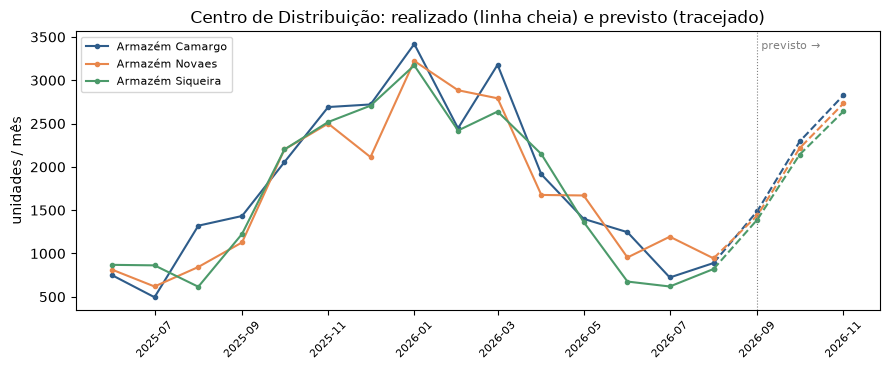

In [7]:
DESDE = dt.date(2025, 6, 1)


def grafico_evolucao(tipo: str, ax) -> None:
    evolucao = evolucao_mensal(previsao, real, tipo, desde=DESDE)
    for i, (nome, parte) in enumerate(evolucao.groupby("location_name")):
        parte = parte.sort_values("mes")
        hist = parte[parte["origem"] == "realizado"]
        prev = parte[parte["origem"] == "previsto"]
        # Liga o último realizado ao primeiro previsto para a curva não quebrar.
        ligado = pd.concat([hist.tail(1), prev])
        ax.plot(hist["mes"], hist["valor"], color=CORES[i % len(CORES)], marker="o", markersize=3, label=nome)
        ax.plot(ligado["mes"], ligado["valor"], color=CORES[i % len(CORES)], linestyle="--", marker="o", markersize=3)
    ax.axvline(MESES[0], color="grey", linewidth=0.8, linestyle=":")
    ax.text(MESES[0], ax.get_ylim()[1] * 0.97, " previsto →", color="grey", va="top", fontsize=8)
    ax.set_title(f"{TIPO_LOCAL[tipo]}: realizado (linha cheia) e previsto (tracejado)")
    ax.set_ylabel("unidades / mês")
    ax.legend(fontsize=8)
    ax.tick_params(axis="x", labelrotation=45, labelsize=8)


fig, ax = plt.subplots(figsize=(9, 3.8))
grafico_evolucao(CD, ax)
plt.tight_layout()
plt.show()

**O que a tabela e o gráfico mostram:** os três CDs sobem de ~1.400–1.500 unidades em setembro para ~2.600–2.800 em novembro, todos com **+89,8%**. O Armazém Camargo lidera em unidades (+1.338) só porque parte do maior volume; a diferença entre o primeiro e o terceiro colocado é de 88 unidades no trimestre inteiro. No gráfico, o trecho tracejado repete o formato da subida de 2025 — é a alta temporada chegando, não um comportamento próprio de algum CD.

## 5. Ponto de Venda

,location_name,cd_associado,criterio_vinculo,mes_1,mes_2,mes_3,var_abs_1_2,var_pct_1_2,var_abs_2_3,var_pct_2_3,cresc_abs_1_3,cresc_pct_1_3,rank_abs,rank_pct
0,Loja Oliveira,Armazém Novaes,mesma região,1443.22,2221.58,2738.70,778.37,53.93,517.12,23.28,1295.48,89.76,1,1
1,Loja Mendonça,Armazém Novaes,mesma UF,1435.88,2210.30,2724.79,774.41,53.93,514.49,23.28,1288.90,89.76,2,2
2,Loja Leão,Armazém Camargo,mesma UF,1419.76,2185.48,2694.19,765.72,53.93,508.71,23.28,1274.43,89.76,3,3


PDV de maior crescimento (mês 1 → mês 3): Loja Oliveira (CD associado: Armazém Novaes) | +1,295.5 unidades | 89.76%


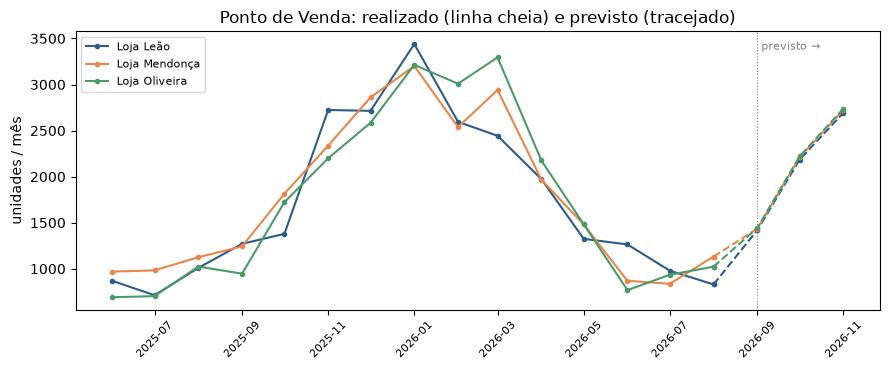

In [8]:
pdvs = trajetoria_por_unidade(previsao, PDV)
display(pdvs[["location_name", "cd_associado", "criterio_vinculo", *COLS_TRAJ[1:]]].round(2))
pdv_vencedor = pdvs.iloc[0]
print(f"PDV de maior crescimento (mês 1 → mês 3): {pdv_vencedor['location_name']}"
      f" (CD associado: {pdv_vencedor['cd_associado']})"
      f" | +{pdv_vencedor['cresc_abs_1_3']:,.1f} unidades | {pdv_vencedor['cresc_pct_1_3']:.2f}%")

fig, ax = plt.subplots(figsize=(9, 3.8))
grafico_evolucao(PDV, ax)
plt.tight_layout()
plt.show()

**O que a tabela e o gráfico mostram:** mesma história nas lojas. A Loja Oliveira lidera por 7 unidades sobre a Mendonça e por 21 sobre a Leão — diferenças pequenas demais para significar algo, num trimestre de mais de 6.000 unidades por loja. Todas crescem os mesmos 89,8%.

O gráfico a seguir junta CDs e PDVs no mesmo ranking, com o percentual escrito ao lado de cada barra — para deixar visível que ele não muda.

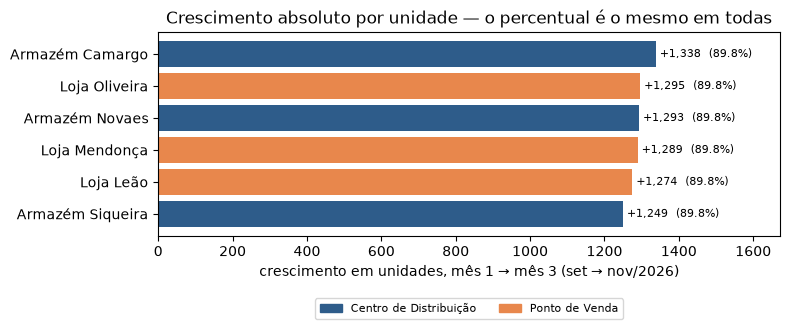

In [9]:
todas = pd.concat(
    [cds.assign(tipo=TIPO_LOCAL[CD], location_type=CD), pdvs.assign(tipo=TIPO_LOCAL[PDV], location_type=PDV)]
).sort_values("cresc_abs_1_3")

fig, ax = plt.subplots(figsize=(8, 3.6))
barras = ax.barh(todas["location_name"], todas["cresc_abs_1_3"], color=[COR_TIPO[t] for t in todas["location_type"]])
ax.bar_label(barras, labels=[f"+{v:,.0f}  ({p:.1f}%)" for v, p in zip(todas["cresc_abs_1_3"], todas["cresc_pct_1_3"])],
             padding=3, fontsize=8)
ax.set_xlim(0, todas["cresc_abs_1_3"].max() * 1.25)
ax.set_xlabel("crescimento em unidades, mês 1 → mês 3 (set → nov/2026)")
ax.set_title("Crescimento absoluto por unidade — o percentual é o mesmo em todas")
handles = [plt.Rectangle((0, 0), 1, 1, color=COR_TIPO[t]) for t in (CD, PDV)]
ax.legend(handles, [TIPO_LOCAL[CD], TIPO_LOCAL[PDV]], fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.28), ncol=2)
plt.tight_layout()
plt.show()

## 6. Contra o mesmo trimestre de 2025

A comparação que retira a estação da conta: o trimestre previsto (set–nov/2026) contra o mesmo trimestre **realizado** um ano antes (set–nov/2025), por unidade. Aqui o índice sazonal já não manda, porque os dois lados estão na mesma estação; o que sobra é o nível que o modelo atribui a cada local frente ao que ele vendeu de fato.

Centros de Distribuição — set–nov/2026 previsto vs set–nov/2025 realizado


,location_name,realizado_ano_anterior,previsto,cresc_abs,cresc_pct,rank_abs,rank_pct,queda
0,Armazém Novaes,5829.0,6388.89,559.89,9.61,1,1,False
1,Armazém Camargo,6179.0,6611.46,432.46,7.00,2,2,False
2,Armazém Siqueira,5945.0,6174.94,229.94,3.87,3,3,False



Pontos de Venda


,location_name,cd_associado,realizado_ano_anterior,previsto,cresc_abs,cresc_pct,rank_abs,rank_pct,queda
0,Loja Oliveira,Armazém Novaes,4869.0,6403.50,1534.50,31.52,1,1,False
1,Loja Mendonça,Armazém Novaes,5394.0,6370.97,976.97,18.11,2,2,False
2,Loja Leão,Armazém Camargo,5374.0,6299.43,925.43,17.22,3,3,False



CD de maior crescimento frente a 2025: Armazém Novaes (+560 unidades, +9.6%)
PDV de maior crescimento frente a 2025: Loja Oliveira (+1,535 unidades, +31.5%)
unidades com queda frente a 2025: 0


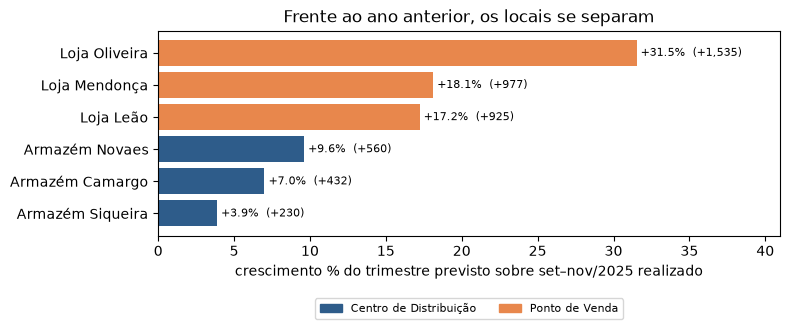

In [10]:
COLS_AA = ["location_name", "realizado_ano_anterior", "previsto", "cresc_abs", "cresc_pct", "rank_abs", "rank_pct", "queda"]
cds_aa = crescimento_vs_ano_anterior(previsao, real, CD)
pdvs_aa = crescimento_vs_ano_anterior(previsao, real, PDV)
assert not cds_aa["referencia_incompleta"].any() and not pdvs_aa["referencia_incompleta"].any(), "faltam meses de 2025 no realizado"

print("Centros de Distribuição — set–nov/2026 previsto vs set–nov/2025 realizado")
display(cds_aa[COLS_AA].round(2))
print("\nPontos de Venda")
display(pdvs_aa[["location_name", "cd_associado", *COLS_AA[1:]]].round(2))

cd_aa_vencedor, pdv_aa_vencedor = cds_aa.iloc[0], pdvs_aa.iloc[0]
print(f"\nCD de maior crescimento frente a 2025: {cd_aa_vencedor['location_name']}"
      f" (+{cd_aa_vencedor['cresc_abs']:,.0f} unidades, {cd_aa_vencedor['cresc_pct']:+.1f}%)")
print(f"PDV de maior crescimento frente a 2025: {pdv_aa_vencedor['location_name']}"
      f" (+{pdv_aa_vencedor['cresc_abs']:,.0f} unidades, {pdv_aa_vencedor['cresc_pct']:+.1f}%)")
print(f"unidades com queda frente a 2025: {int(cds_aa['queda'].sum() + pdvs_aa['queda'].sum())}")

todas_aa = pd.concat([cds_aa.assign(location_type=CD), pdvs_aa.assign(location_type=PDV)]).sort_values("cresc_pct")
fig, ax = plt.subplots(figsize=(8, 3.6))
barras = ax.barh(todas_aa["location_name"], todas_aa["cresc_pct"], color=[COR_TIPO[t] for t in todas_aa["location_type"]])
ax.bar_label(barras, labels=[f"{p:+.1f}%  (+{v:,.0f})" for v, p in zip(todas_aa["cresc_abs"], todas_aa["cresc_pct"])],
             padding=3, fontsize=8)
ax.set_xlim(0, todas_aa["cresc_pct"].max() * 1.3)
ax.set_xlabel("crescimento % do trimestre previsto sobre set–nov/2025 realizado")
ax.set_title("Frente ao ano anterior, os locais se separam")
ax.legend(handles, [TIPO_LOCAL[CD], TIPO_LOCAL[PDV]], fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.28), ncol=2)
plt.tight_layout()
plt.show()

**O que as tabelas mostram:** frente a 2025 os locais deixam de ser iguais. Entre os CDs, o **Armazém Novaes** passa à frente (+9,6%), o Camargo — líder em volume — cresce +7,0% e o Siqueira quase não sai do lugar (+3,9%). Entre as lojas, a **Loja Oliveira** cresce +31,5%, bem acima de Mendonça (+18,1%) e Leão (+17,2%). Nenhuma unidade cai.

Por que o CD vencedor muda: o ranking dentro do horizonte só olha o volume previsto para 2026, e o Camargo tem o maior. O ranking frente a 2025 olha o quanto esse volume supera o que a unidade vendeu na mesma estação do ano passado — e o Camargo já vendia muito em set–nov/2025, então o salto relativo é menor. As lojas crescem mais que os armazéns pela mesma razão: venderam menos em 2025, e a régua do modelo (média do grupo nos últimos 12 meses, corrigida por tendência) atribui a todas um nível parecido para 2026.

## 7. Quais produtos puxam o crescimento

Para as unidades vencedoras, a contribuição de cada produto nas duas definições. Na definição principal (mês 1 → 3) a contribuição de um produto é proporcional ao seu volume — é a mesma constante de sempre —, então os "maiores contribuintes" são só os produtos de maior previsão. Frente a 2025 a contribuição é `previsto − realizado` por produto, que traz informação: mostra onde o modelo espera vender mais do que a unidade vendeu.

CD Armazém Novaes: 1,009 produtos | crescimento frente a 2025 = +560 unidades | top 10 respondem por 13% | 41 produtos fazem metade


,sku,product_name,category_name,realizado_ano_anterior,previsto,cresc_ano_anterior_abs,mes_1,mes_3,cresc_abs_1_3
0,LHN-488283,Sonar Transducer 7487,Sonares e Transdutores,0.0,7.1,7.1,1.6,3.1,1.4
1,LHN-028460,Sonar Transducer 8490,Sonares e Transdutores,0.0,7.1,7.1,1.6,3.0,1.4
2,LHN-926760,Sonar Transducer 8490,Sonares e Transdutores,0.0,7.1,7.1,1.6,3.0,1.4
3,LHN-926521,Motor de Popa 8461,Motores,0.0,7.0,7.0,1.6,3.0,1.4
4,LHN-568743,Sonar Transducer 1176,Sonares e Transdutores,0.0,7.0,7.0,1.6,3.0,1.4
5,LHN-032019,Sonar Transducer 4635,Sonares e Transdutores,0.0,7.0,7.0,1.6,3.0,1.4
6,LHN-383027,Sonar Transducer 4574,Sonares e Transdutores,0.0,7.0,7.0,1.6,3.0,1.4
7,LHN-084998,Sonar Transducer 6909,Sonares e Transdutores,0.0,7.0,7.0,1.6,3.0,1.4
8,LHN-841359,Cabo Náutico 9048,Cabos,0.0,6.9,6.9,1.6,3.0,1.4
9,LHN-511507,Sonar Transducer 7193,Sonares e Transdutores,0.0,6.9,6.9,1.6,3.0,1.4


entre os 10 maiores contribuintes, 10 não venderam nada em set–nov/2025
por categoria (12 categorias), as 5 que mais contribuem:


,realizado_ano_anterior,previsto,cresc_ano_anterior_abs,share_do_crescimento
category_name,,,,
GPS & Plotters,504.0,629.02,125.02,0.22
Motores,636.0,750.76,114.76,0.20
Sonares e Transdutores,405.0,512.19,107.19,0.19
Baterias e Sistemas Elétricos,378.0,471.97,93.97,0.17
Instrumentos de Navegação,574.0,655.29,81.29,0.15


categorias com queda frente a 2025: Velas (-23), Pintura Marítima (-58)
PDV Loja Oliveira: 1,009 produtos | crescimento frente a 2025 = +1,535 unidades | top 10 respondem por 5% | 113 produtos fazem metade


,sku,product_name,category_name,realizado_ano_anterior,previsto,cresc_ano_anterior_abs,mes_1,mes_3,cresc_abs_1_3
0,LHN-444755,Tinta Antifouling 874,Pintura Marítima,0.0,7.5,7.5,1.7,3.2,1.5
1,LHN-771654,Tinta Antifouling 6054,Pintura Marítima,0.0,7.4,7.4,1.7,3.2,1.5
2,LHN-630683,Tinta Antifouling 9500,Pintura Marítima,0.0,7.4,7.4,1.7,3.2,1.5
3,LHN-141578,Tinta Antifouling 9500,Pintura Marítima,0.0,7.4,7.4,1.7,3.2,1.5
4,LHN-561045,Tinta Antifouling 901,Pintura Marítima,0.0,7.4,7.4,1.7,3.2,1.5
5,LHN-900424,Tinta Antifouling 8939,Pintura Marítima,0.0,7.4,7.4,1.7,3.1,1.5
6,LHN-529896,Tinta Antifouling 3620,Pintura Marítima,0.0,7.3,7.3,1.6,3.1,1.5
7,LHN-016677,Tinta Antifouling 874,Pintura Marítima,0.0,7.3,7.3,1.6,3.1,1.5
8,LHN-433136,Tinta Antifouling 6959,Pintura Marítima,0.0,7.3,7.3,1.6,3.1,1.5
9,LHN-156424,Tinta Antifouling 3228,Pintura Marítima,0.0,7.3,7.3,1.6,3.1,1.5


entre os 10 maiores contribuintes, 10 não venderam nada em set–nov/2025
por categoria (12 categorias), as 5 que mais contribuem:


,realizado_ano_anterior,previsto,cresc_ano_anterior_abs,share_do_crescimento
category_name,,,,
Instrumentos de Navegação,449.0,655.26,206.26,0.13
GPS & Plotters,400.0,573.73,173.73,0.11
Âncoras,281.0,437.29,156.29,0.10
Velas,313.0,464.70,151.70,0.10
Sonares e Transdutores,351.0,495.04,144.04,0.09


categorias com queda frente a 2025: nenhuma


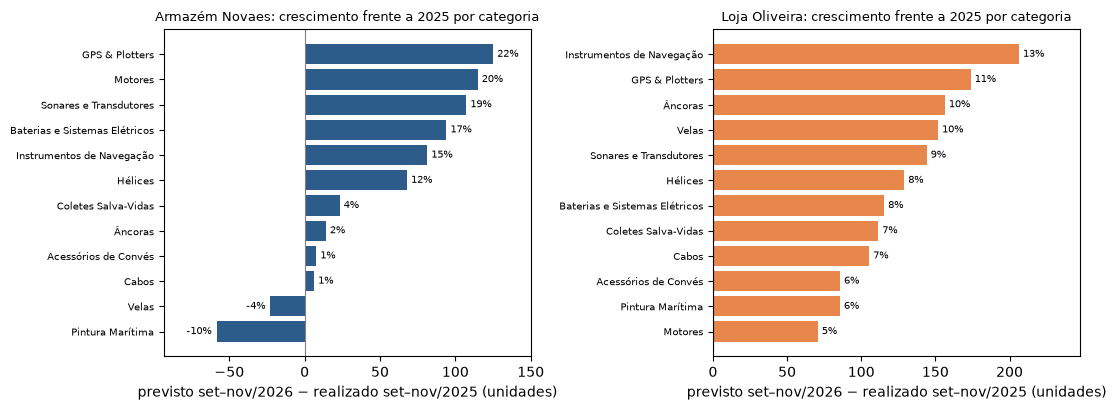

In [11]:
TOP_N = 10


def resumo_contribuicao(sk_location: str, rotulo: str) -> pd.DataFrame:
    contrib = contribuicao_produtos(previsao, real, produtos, sk_location)
    conc = concentracao(contrib["cresc_ano_anterior_abs"], top_n=TOP_N)
    print(f"{rotulo}: {conc['n']:,} produtos | crescimento frente a 2025 = {conc['total']:+,.0f} unidades"
          f" | top {TOP_N} respondem por {conc['share_top_n']:.0%} | {conc['n_para_metade']} produtos fazem metade")
    display(
        contrib.head(TOP_N)[["sku", "product_name", "category_name", "realizado_ano_anterior", "previsto",
                             "cresc_ano_anterior_abs", "mes_1", "mes_3", "cresc_abs_1_3"]].round(1)
    )
    zerados = int((contrib.head(TOP_N)["realizado_ano_anterior"] == 0).sum())
    print(f"entre os {TOP_N} maiores contribuintes, {zerados} não venderam nada em set–nov/2025")
    por_categoria = (
        contrib.groupby("category_name")[["realizado_ano_anterior", "previsto", "cresc_ano_anterior_abs"]]
        .sum()
        .sort_values("cresc_ano_anterior_abs", ascending=False)
    )
    por_categoria["share_do_crescimento"] = por_categoria["cresc_ano_anterior_abs"] / conc["total"]
    print(f"por categoria ({len(por_categoria)} categorias), as 5 que mais contribuem:")
    display(por_categoria.head(5).round(2))
    em_queda = por_categoria[por_categoria["cresc_ano_anterior_abs"] < 0]
    print("categorias com queda frente a 2025: " + (", ".join(
        f"{c} ({v:+.0f})" for c, v in em_queda["cresc_ano_anterior_abs"].items()) or "nenhuma"))
    return contrib, por_categoria


contrib_cd, cat_cd = resumo_contribuicao(cd_aa_vencedor["sk_location"], f"CD {cd_aa_vencedor['location_name']}")
contrib_pdv, cat_pdv = resumo_contribuicao(pdv_aa_vencedor["sk_location"], f"PDV {pdv_aa_vencedor['location_name']}")

# Por SKU o gráfico seria dez barras iguais (ver tabela acima); por categoria a decomposição tem leitura.
fig, eixos = plt.subplots(1, 2, figsize=(11, 4.2), sharey=False)
for ax, por_cat, titulo, cor in (
    (eixos[0], cat_cd, cd_aa_vencedor["location_name"], COR_TIPO[CD]),
    (eixos[1], cat_pdv, pdv_aa_vencedor["location_name"], COR_TIPO[PDV]),
):
    ordenado = por_cat.sort_values("cresc_ano_anterior_abs")
    barras = ax.barh(ordenado.index, ordenado["cresc_ano_anterior_abs"], color=cor)
    ax.bar_label(barras, labels=[f"{v:.0%}" for v in ordenado["share_do_crescimento"]], padding=3, fontsize=7)
    ax.set_xlim(min(0.0, ordenado["cresc_ano_anterior_abs"].min() * 1.6), ordenado["cresc_ano_anterior_abs"].max() * 1.2)
    ax.axvline(0, color="grey", linewidth=0.8)
    ax.set_title(f"{titulo}: crescimento frente a 2025 por categoria", fontsize=9)
    ax.set_xlabel("previsto set–nov/2026 − realizado set–nov/2025 (unidades)")
    ax.tick_params(axis="y", labelsize=7)
plt.tight_layout()
plt.show()

**O que as tabelas mostram:** o crescimento frente a 2025 é **difuso**, não concentrado. No Armazém Novaes, os 10 produtos que mais contribuem respondem por só 13% dos +560 — são precisos 41 produtos para chegar à metade. Na Loja Oliveira é ainda mais espalhado: top 10 = 5% dos +1.535, e 113 produtos fazem metade.

E os "maiores contribuintes" têm todos a mesma cara: **não venderam nada em set–nov/2025** e recebem uma previsão de ~7 unidades no trimestre — o nível médio do seu grupo. Isso não é um sinal de produto; é a limitação já registrada no notebook 06 aparecendo aqui: o modelo quase não diferencia produtos dentro de categoria × loja, então quem vendeu zero ano passado "cresce" até a média do grupo. Por isso a leitura útil é por **categoria**, não por SKU: no Novaes o crescimento vem de GPS & Plotters (22%), Motores (20%), Sonares e Transdutores (19%), Baterias (17%) e Instrumentos de Navegação (15%); na Oliveira, de Instrumentos de Navegação (13%), GPS & Plotters (11%), Âncoras (10%), Velas (10%) e Sonares (9%). Em nenhum dos dois há uma categoria dominante. No Novaes duas categorias **caem** frente a 2025 — Pintura Marítima (−58 unidades) e Velas (−23) —, porque venderam acima da média do grupo em set–nov/2025 e o modelo as traz de volta ao nível; na Oliveira todas as 12 categorias sobem.

## 8. Robustez: o GLM Tweedie conta a mesma história?

O notebook 06 gravou também a partição `glm_tweedie` (power 1,3), que empatou com o Poisson no teste. Se a análise acima dependesse de detalhes do modelo, os vencedores mudariam aqui.

In [12]:
mensal_tw = ler(model_config.forecast_monthly_target, "model_name = 'glm_tweedie'")
mensal_tw["demanda_prevista"] = pd.to_numeric(mensal_tw["demanda_prevista"]).astype(float)
validar_previsao_mensal(mensal_tw)
previsao_tw = enriquecer(mensal_tw, locais)

linhas = []
for tipo in (CD, PDV):
    traj = trajetoria_por_unidade(previsao_tw, tipo).iloc[0]
    aa = crescimento_vs_ano_anterior(previsao_tw, real, tipo).iloc[0]
    linhas.append({"tipo": TIPO_LOCAL[tipo],
                   "vencedor mês 1→3 (Tweedie)": traj["location_name"], "cresc_abs_1_3": round(traj["cresc_abs_1_3"], 1),
                   "vencedor vs 2025 (Tweedie)": aa["location_name"], "cresc_pct_vs_2025": round(aa["cresc_pct"], 1)})
display(pd.DataFrame(linhas))
mesmos = (
    linhas[0]["vencedor mês 1→3 (Tweedie)"] == cd_vencedor["location_name"]
    and linhas[0]["vencedor vs 2025 (Tweedie)"] == cd_aa_vencedor["location_name"]
    and linhas[1]["vencedor mês 1→3 (Tweedie)"] == pdv_vencedor["location_name"]
    and linhas[1]["vencedor vs 2025 (Tweedie)"] == pdv_aa_vencedor["location_name"]
)
print("mesmos vencedores que o Poisson:", mesmos)

,tipo,vencedor mês 1→3 (Tweedie),cresc_abs_1_3,vencedor vs 2025 (Tweedie),cresc_pct_vs_2025
0,Centro de Distribuição,Armazém Camargo,1336.1,Armazém Novaes,9.5
1,Ponto de Venda,Loja Oliveira,1294.0,Loja Oliveira,31.4


mesmos vencedores que o Poisson: True


**O que a tabela mostra:** o Tweedie aponta os mesmos vencedores nas duas definições — Camargo (+1.336 contra +1.338 do Poisson) e Oliveira (+1.294 contra +1.295) dentro do horizonte; Novaes (+9,5% contra +9,6%) e Oliveira (+31,4% contra +31,5%) frente a 2025. As diferenças estão na segunda casa decimal, como esperado de dois modelos que empataram no teste.

## Conclusão

**Resposta à pergunta, ao pé da letra:** nos três meses previstos (set–nov/2026), o CD com maior crescimento de demanda é o **Armazém Camargo** (+1.338 unidades do mês 1 para o mês 3, de 1.490 para 2.828) e o PDV é a **Loja Oliveira** (+1.295, de 1.443 para 2.739; CD associado: Armazém Novaes).

**A ressalva que muda a leitura:** o crescimento percentual é **89,8% em todas as seis unidades**, porque a previsão mensal reparte o total de 3 meses por um índice sazonal único. Dentro do horizonte, o ranking de crescimento é o ranking de volume — e as diferenças de volume entre as unidades são pequenas (88 unidades entre o primeiro e o terceiro CD; 21 entre a primeira e a terceira loja).

**Onde os locais se separam de verdade:** frente ao mesmo trimestre de 2025, o **Armazém Novaes** é o CD que mais cresce (+9,6%), o Camargo fica em +7,0% e o Siqueira em +3,9%; entre as lojas, a **Oliveira** cresce +31,5%, contra +18,1% (Mendonça) e +17,2% (Leão). Nenhuma unidade cai. Esse crescimento é espalhado por todo o catálogo — nenhuma categoria domina e os SKUs que mais "contribuem" são os que não venderam em 2025 e recebem o nível do grupo.

**Limites desta análise:** (1) o vínculo PDV → CD é uma hipótese geográfica, não um dado; (2) o percentual dentro do horizonte não discrimina por construção; (3) a previsão por local é quase uniforme porque a régua fixa o nível por categoria × local e o modelo corrige pouco — diferenças pequenas entre unidades não devem ser lidas como sinal; (4) o realizado de 2025 tem a mesma cara de dado simulado que o resto do projeto.